### Problem 15 : Fine-tuning and un-finetuning - when a customer leaves

⏱️ ~45 min · 🧭 Stage 6 (Real-world Responsible AI), rung 9 · 📄 `resources/papers/08-course-additions/2021-hu-lora-low-rank-adaptation.pdf`, `resources/papers/08-course-additions/2023-ilharco-task-arithmetic.pdf`, `resources/papers/02-exact-unlearning/2019-bourtoule-sisa-machine-unlearning.pdf`

> 🔗 **Building on Problem 14 :** every model so far was trained once, from scratch, on one dataset. Enterprise AI is
> built differently : a **base model** trained on broad data, then **fine-tuned** for each customer on their private
> data. That changes what "unlearn" means, and it gives us a new place to make it cheap.

A SaaS vendor sells a document reader that digitises handwritten figures on scanned forms. Three banks are customers
(**tenants**). Each bank's scanners produce a different look : Northbank's are thick and smudged, Eastbank's are offset
by a pixel, and Southbank's archive scans are **colour-inverted**. The vendor adapts the base model to each bank with
that bank's own labelled forms.

Southbank terminates its contract. The data processing agreement says : *"On termination, the processor deletes all
customer data **and any models or model components derived from it** within 30 days."* That clause is now common,
and after the FTC's model-deletion orders (ReadFIRST, section 2) it is enforced.

> 🟢 **In plain words :** a general-purpose model is like a trained chef. Each restaurant teaches the chef its own
> recipes. When a restaurant leaves, the chef must forget *its* recipes but keep everybody else's. If each restaurant's
> recipes were written in a separate notebook, you just throw that notebook away. If they were all mixed into one, you
> have a problem.

> 🔴 **For practitioners :** three architectures, three answers. (1) **Per-tenant adapters** (LoRA) over a frozen base :
> deleting the adapter is exact and free. (2) **One shared fine-tune** on pooled tenant data : exact unlearning =
> re-fine-tune from the saved base checkpoint without the tenant, which costs a fine-tune, not a pre-training. This is
> SISA's checkpoint idea on the *time* axis. (3) **Approximate un-finetuning** by task-vector negation : cheap but
> uncalibrated. And a trap : if the vendor ever used tenant data to improve the **base**, the deletion cascades through
> every tenant.

**TASK :** Build the base, the shared fine-tune and per-tenant LoRA adapters (in NumPy), remove Southbank from each,
prove which removals are exact, and measure what each one costs.

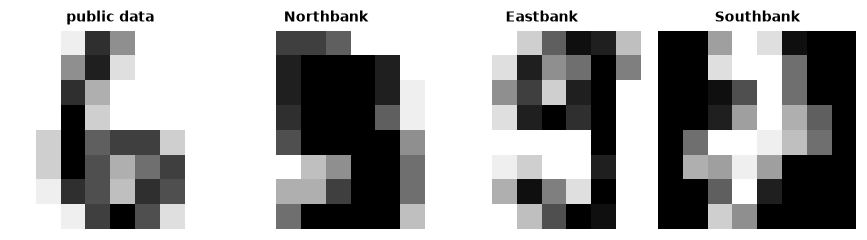

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from mul import lab, train, viz
from mul.nn import MLP, LoRA
viz.style()

d = load_digits()
rng = np.random.default_rng(0)
perm = rng.permutation(len(d.data))
X, y = d.data[perm].astype(np.float32), d.target[perm]
public = np.arange(700)                                  # the vendor's own, public training data
private = np.arange(700, len(X))                         # split between the three banks

shift = lambda Z: np.roll(Z.reshape(-1, 8, 8), 1, axis=2).reshape(-1, 64).astype(np.float32)
SCANNER = {"Northbank": lab.thick_marker, "Eastbank": shift, "Southbank": lambda Z: (16 - Z).astype(np.float32)}
TENANTS = list(SCANNER)
T = {}
for name, rows in zip(TENANTS, np.array_split(private, 3)):
    tr, te = rows[:250], rows[250:]
    T[name] = dict(Xtr=SCANNER[name](X[tr]), ytr=y[tr], Xte=SCANNER[name](X[te]), yte=y[te])

fig, axes = plt.subplots(1, 4, figsize=(8, 2.2))
axes[0].imshow(X[public[0]].reshape(8, 8), cmap="gray_r"); axes[0].set_title("public data", fontsize=9)
for ax, name in zip(axes[1:], TENANTS):
    ax.imshow(T[name]["Xtr"][0].reshape(8, 8), cmap="gray_r"); ax.set_title(name, fontsize=9)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

#### Step 1 : Train - a base model, then two ways to fine-tune it

The **base** model (64 → 128 → 128 → 10) is trained on the vendor's public data only. Then the vendor customises it in
one of two ways :

1. **Shared fine-tune** : fine-tune *all* weights of a copy of the base on the pooled data of all three banks. One
   model serves everyone.
2. **Per-tenant LoRA adapters** : keep the base **frozen**, and for each bank train a small low-rank adapter
   `ΔW = A·B` (rank 4) on *that bank's data only*. At serving time, each bank's requests use the base plus its own
   adapter. (The `LoRA` class in `mul/nn.py` is ~80 lines, gradient-checked in `tests/`.)

In [2]:
# Step 1: base, shared fine-tune, per-tenant adapters  (cost = example-gradients, as in earlier problems)
BASE = dict(epochs=60, lr=1e-3, batch_size=64)
FT = dict(epochs=30, lr=5e-4, batch_size=32)
ADAPT = dict(epochs=60, lr=3e-3, batch_size=32)
cost = {}

base = train.fit(lambda: MLP(64, 10, (128, 128)), X[public], y[public], seed=0, **BASE)
cost["pre-train base"] = BASE["epochs"] * len(public)

def pooled(names):
    return np.concatenate([T[n]["Xtr"] for n in names]), np.concatenate([T[n]["ytr"] for n in names])

def shared_finetune(names, seed=1):
    Xp, yp = pooled(names)
    return train.fit(train.clone(base), Xp, yp, seed=seed, **FT)

shared = shared_finetune(TENANTS)
cost["shared fine-tune (3 banks)"] = FT["epochs"] * sum(len(T[n]["ytr"]) for n in TENANTS)

adapters = {n: train.fit(LoRA(base, rank=4, seed=10 + i), T[n]["Xtr"], T[n]["ytr"], seed=1, **ADAPT) for i, n in enumerate(TENANTS)}
cost["one adapter"] = ADAPT["epochs"] * 250

def report(models):
    """Accuracy of each model on each bank's held-out forms, plus Southbank's own TRAINING forms."""
    rows = {}
    for label, m in models.items():
        get = (lambda n: m[n]) if isinstance(m, dict) else (lambda n: m)        # a dict = one adapter per bank
        rows[label] = {**{n: train.accuracy(get(n), T[n]["Xte"], T[n]["yte"]) if get(n) is not None else np.nan for n in TENANTS},
                       "Southbank TRAIN forms": train.accuracy(get("Southbank"), T["Southbank"]["Xtr"], T["Southbank"]["ytr"]) if get("Southbank") is not None else np.nan}
    return pd.DataFrame(rows).T

print(f"{base!r}\n{adapters['Southbank']!r}   ({adapters['Southbank'].n_params() / base.n_params():.1%} of the base)")
print(report({"base only": base, "shared fine-tune": shared, "per-tenant adapters": adapters}).round(3).to_string())

MLP(64 -> 128 -> 128 -> 10, 26,122 params)
LoRA(rank 4 on MLP(64 -> 128 -> 128 -> 10, 26,122 params): 2,344 trainable params)   (9.0% of the base)
                     Northbank  Eastbank  Southbank  Southbank TRAIN forms
base only                0.440     0.250      0.009                  0.016
shared fine-tune         0.871     0.888      0.896                  1.000
per-tenant adapters      0.828     0.914      0.843                  1.000


The base model cannot read the banks' scans, least of all Southbank's inverted ones. Both customisation strategies fix
that. Each adapter has about 9% of the base model's parameters and only ever saw one bank's data.

#### Step 2 : Show the issue - Southbank is inside the models

Look at the last column. Both the shared model and Southbank's adapter are 100% right on Southbank's **training**
forms and noticeably less on its held-out forms : they memorised its data, exactly like Carol in Problem 4. The contract
requires removing that, and anything derived from it.

#### Step 3 : Untrain - three ways to remove a tenant

In [3]:
# Step 3a: per-tenant adapters - delete Southbank's adapter
adapters_after = {n: (a if n != "Southbank" else None) for n, a in adapters.items()}
untouched = all(train.weights_equal(adapters_after[n], adapters[n]) for n in ["Northbank", "Eastbank"])
print(f"Northbank's and Eastbank's adapters bit-for-bit unchanged: {untouched};  frozen base unchanged: True by construction")
cost["delete adapter"] = 0

# Step 3b: shared model - EXACT un-finetuning: re-fine-tune the saved base checkpoint on the remaining banks
refit = shared_finetune(["Northbank", "Eastbank"])
cost["re-fine-tune from base (exact)"] = FT["epochs"] * 500

# Step 3c: shared model - APPROXIMATE un-finetuning by task-vector negation (Ilharco et al. 2023)
#   task vector of Southbank: tau = (base fine-tuned on Southbank alone) - base ;  model' = shared - lambda * tau
southbank_only = shared_finetune(["Southbank"])
cost["task-vector negation"] = FT["epochs"] * 250
def negate(lam):
    m = train.clone(shared)
    m.params = [s - lam * (c - b) for s, c, b in zip(shared.params, southbank_only.params, base.params)]
    return m
negated = {lam: negate(lam) for lam in [0.25, 0.5, 0.75, 1.0, 1.5]}

Northbank's and Eastbank's adapters bit-for-bit unchanged: True;  frozen base unchanged: True by construction


Notice what 3c needs : a model fine-tuned on **Southbank's data**. Either you computed and stored the task vector when
Southbank onboarded, or you need its data again *now*, after the contract says it must be deleted.

#### Step 4 : Show the result

In [4]:
# Step 4: every option side by side, against the gold standard (re-fine-tunes with 5 seeds, never saw Southbank)
gold = [shared_finetune(["Northbank", "Eastbank"], seed=s) for s in range(100, 105)]
G = report({f"gold {s}": g for s, g in enumerate(gold)})
band_mean, half = G.mean(), np.maximum(2 * G.std(ddof=0), 0.03)          # same half-width rule as audit.gate

options = {"shared fine-tune (before)": shared, "re-fine-tune from base (exact)": refit,
           **{f"task-vector negation λ={lam}": m for lam, m in negated.items()},
           "per-tenant adapters (Southbank's deleted)": adapters_after}
R = report(options)
print("gold band (5 re-fine-tunes that never saw Southbank; mean ± max(2 std, 3 points)):")
print(pd.DataFrame({"mean": band_mean, "±": half}).T.round(3).to_string()); print()
print(R.round(3).to_string())

gold band (5 re-fine-tunes that never saw Southbank; mean ± max(2 std, 3 points)):
      Northbank  Eastbank  Southbank  Southbank TRAIN forms
mean      0.853     0.881      0.038                  0.062
±         0.030     0.030      0.030                  0.030

                                           Northbank  Eastbank  Southbank  Southbank TRAIN forms
shared fine-tune (before)                      0.871     0.888      0.896                  1.000
re-fine-tune from base (exact)                 0.845     0.879      0.017                  0.056
task-vector negation λ=0.25                    0.845     0.853      0.574                  0.724
task-vector negation λ=0.5                     0.828     0.828      0.148                  0.156
task-vector negation λ=0.75                    0.819     0.776      0.043                  0.040
task-vector negation λ=1.0                     0.793     0.724      0.009                  0.004
task-vector negation λ=1.5                     0.724     

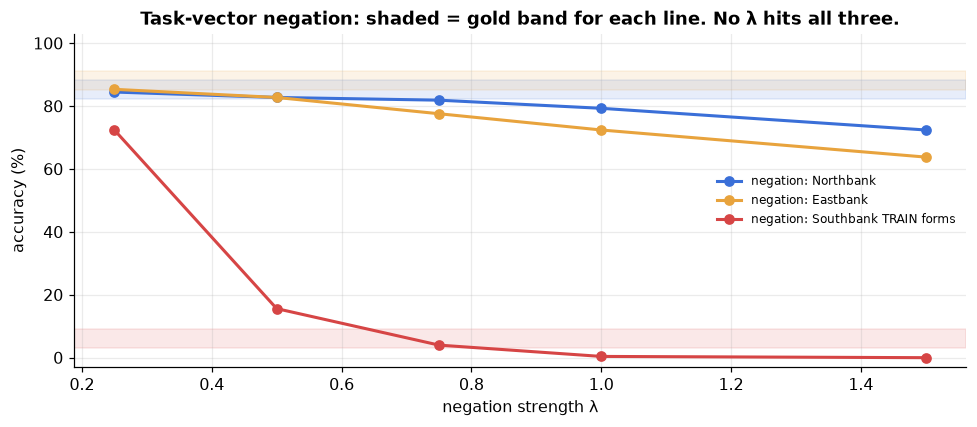

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
lams = list(negated)
for n, c in [("Northbank", viz.RETAIN), ("Eastbank", viz.ACCENT), ("Southbank TRAIN forms", viz.FORGET)]:
    ax.plot(lams, [100 * R.loc[f"task-vector negation λ={l}", n] for l in lams], "o-", color=c, lw=2, label=f"negation: {n}")
    ax.axhspan(100 * (band_mean[n] - half[n]), 100 * (band_mean[n] + half[n]), color=c, alpha=0.12)
ax.set_xlabel("negation strength λ"); ax.set_ylabel("accuracy (%)"); ax.set_ylim(-3, 103)
ax.set_title("Task-vector negation: shaded = gold band for each line. No λ hits all three."); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Read that again.** For the shared model, task-vector negation is a dial with no right setting. Turn it up enough to
erase Southbank's training forms, and the other banks lose accuracy they would keep under an exact re-fine-tune. Turn
it down to protect them, and Southbank's data is still partly recognised. It is the Problem 8 story (gradient ascent
without a reference) in a new costume. And choosing λ needs the gold standard, which we would not have.

The exact re-fine-tune lands in the gold band on every column : it *is* one of those models, with a different seed.

#### Step 5 : Prove it - and price it

What did each exact option cost, compared with what most people assume "retraining" means ?

In [6]:
# Step 5a: the bill for one tenant deletion
bill = pd.Series({"retrain everything (pre-train + fine-tune)": cost["pre-train base"] + FT["epochs"] * 500,
                  "re-fine-tune from saved base (exact)": cost["re-fine-tune from base (exact)"],
                  "task-vector negation (approximate)": cost["task-vector negation"],
                  "delete the tenant's adapter (exact)": cost["delete adapter"]}, name="example-gradients")
print(bill.to_frame().assign(**{"% of full retrain": (100 * bill / bill.iloc[0]).round(1)}).to_string())

                                            example-gradients  % of full retrain
retrain everything (pre-train + fine-tune)              57000              100.0
re-fine-tune from saved base (exact)                    15000               26.3
task-vector negation (approximate)                       7500               13.2
delete the tenant's adapter (exact)                         0                0.0


Two lessons in one table.

- **Keep the base checkpoint.** "Retraining" a fine-tuned model never has to start before the point where the tenant's
  data entered. Here that already saves the whole pre-training run, and for a foundation model that is the difference
  between millions of dollars and a fine-tuning job. This is SISA's slice checkpoints (Problem 7) applied to the
  model's history.
- **Isolate tenants by design.** With per-tenant adapters, the exact deletion is free and *provably* touches no one
  else. The price is paid up front : one adapter per tenant, and a serving stack that routes each request to the right
  adapter (multi-adapter serving is standard for LLMs today).

#### Step 5b : The cascade - when tenant data reached the base

Now the trap. Suppose the vendor, to "improve the product for everyone", once continued training the **base** on a
sample of every bank's data, then trained the adapters on top of that improved base. Southbank's data is now inside
the frozen base that every tenant's adapter depends on.

In [7]:
# Step 5b: base v2 trained with tenant data -> adapters on top -> Southbank leaves
def base_v2_without(excluded):
    Xs = [X[public]] + [T[n]["Xtr"][:100] for n in TENANTS if n not in excluded]
    ys = [y[public]] + [T[n]["ytr"][:100] for n in TENANTS if n not in excluded]
    return train.fit(lambda: MLP(64, 10, (128, 128)), np.concatenate(Xs), np.concatenate(ys), seed=0, **BASE)

v2 = base_v2_without([])
ad_v2 = {n: train.fit(LoRA(v2, rank=4, seed=10 + i), T[n]["Xtr"], T[n]["ytr"], seed=1, **ADAPT) for i, n in enumerate(TENANTS)}
v2_clean = base_v2_without(["Southbank"])                        # the only exact fix: rebuild the base without her data

stale = {n: ad_v2[n].copy() for n in ["Northbank", "Eastbank"]}
for a in stale.values():
    a.base = v2_clean                                              # old adapters, plugged into the rebuilt base
rebuilt = {n: train.fit(LoRA(v2_clean, rank=4, seed=10 + i), T[n]["Xtr"], T[n]["ytr"], seed=1, **ADAPT) for i, n in enumerate(["Northbank", "Eastbank"])}

acc = lambda m, n: train.accuracy(m, T[n]["Xte"], T[n]["yte"])
cascade = pd.DataFrame({
    "adapters on base v2 (before)": {n: acc(ad_v2[n], n) for n in ["Northbank", "Eastbank"]},
    "old adapters on rebuilt base": {n: acc(stale[n], n) for n in ["Northbank", "Eastbank"]},
    "adapters re-trained on rebuilt base": {n: acc(rebuilt[n], n) for n in ["Northbank", "Eastbank"]}}).T
print(cascade.round(3).to_string())
cascade_cost = BASE["epochs"] * (len(public) + 200) + 2 * cost["one adapter"]
print(f"\ncost of deleting Southbank now: {cascade_cost:,} example-gradients "
      f"(rebuild base + re-train EVERY remaining adapter) vs {cost['delete adapter']} with a clean base")

                                     Northbank  Eastbank
adapters on base v2 (before)             0.879     0.897
old adapters on rebuilt base             0.862     0.845
adapters re-trained on rebuilt base      0.888     0.914

cost of deleting Southbank now: 84,000 example-gradients (rebuild base + re-train EVERY remaining adapter) vs 0 with a clean base


Once tenant data reaches the base, deletion **cascades** : the base must be rebuilt from the last checkpoint that did
not contain Southbank's data, and every other tenant's adapter must be re-trained. Two reasons. An adapter is tuned to
the exact base it was trained on, so the old adapters lose accuracy on the rebuilt base (the middle row). And they were
*optimised against a base that contained Southbank's data*, so under a "derived models" clause they are derived too. One customer leaving now costs a full pre-training run plus a
fine-tune for every remaining customer.

> 🔴 **For practitioners :** this is why enterprise AI contracts and architectures need a **data lineage** record :
> for every checkpoint (base, adapter, merged model, distilled model), which tenants' data reached it, directly or
> through a parent. Unlearning then becomes a graph query : *"which artefacts descend from Southbank's data, and what
> is the cheapest exact rebuild?"* Keep pre-tenant checkpoints, keep the base clean of tenant data (or isolate any
> tenant-data improvements in their own adapters), and never merge adapters trained on different tenants into a
> single set of weights you cannot take apart again. Problem 17 turns this into a playbook.

----
#### OUTCOME :

| Architecture | How Southbank is removed | Exact? | Cost (% of a full retrain) | Touches other tenants? |
|---|---|---|---|---|
| Per-tenant adapters, clean base | delete the adapter | ✅ | **0%** | ❌ no (bit-for-bit) |
| Shared fine-tune | re-fine-tune from the saved base | ✅ | a fraction (fine-tune only) | ✅ yes, everyone gets a new model |
| Shared fine-tune | task-vector negation | ❌ | small, **and needs her data or a stored task vector** | ✅ yes, and hurts them |
| Tenant data in the base | rebuild base + re-train every adapter | ✅ | **more than 100%** | ✅ yes, all of them |

#### Key Takeaways :

- "Un-finetuning" exactly never needs to go further back than the checkpoint **before** the tenant's data entered.
  Keep that checkpoint.
- **Per-tenant adapters** make tenant deletion exact, free and isolated. This is the strongest architectural lever in
  enterprise unlearning.
- **Task-vector negation** is an uncalibrated dial : it cannot match the exact result on the leaving tenant and the
  remaining ones at the same time.
- Tenant data in the **base** turns every deletion into a cascade. Track **lineage** for every artefact.
- Contracts that say "delete derived models" are only cheap to honour if the architecture was designed for it.

#### TASK :
1. Increase the adapter rank to 16 and to 1. How do accuracy, memorisation of Southbank's training forms and adapter
   size change? Which rank would you choose, and what does memorisation mean for privacy here?
2. Train a **single shared adapter** on the pooled data of all three banks (one `LoRA` on the stacked data). Is deleting
   Southbank still free? What is the cheapest *exact* fix?
3. Merge each adapter into its own copy of the base with `.merged()` for faster serving. Does that change how Southbank
   is deleted? Now merge **all three** adapters into one set of weights (sum the deltas). What happens to accuracy, and
   to deletion?
4. Draw the lineage graph for the cascade scenario (base v1 → base v2 → adapters). Write the query that answers "which
   artefacts must be rebuilt if Eastbank leaves?"

#### ❓ Open question → Problem 16
Our "tenants" were scanner styles, so removing their data removed a capability too. **What about a language model
fine-tuned on a company directory, where what must go is a specific *fact*, such as a phone number, that the model can
recite word for word, and where a capability-preserving "refusal" can look like forgetting?** That is Problem 16.